# Classificação Multiclasse

## Importações inicias

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [121]:
import zipfile
import struct

In [122]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## Funções auxiliares

In [123]:
def carregar_imagens(arquivo):
    with zipfile.ZipFile(caminho, "r") as z:
        dados = z.read(arquivo)

    # Cabeçalho IDX: número mágico, quantidade, linhas e colunas
    magic, n, linhas, colunas = struct.unpack(">IIII", dados[:16])

    assert magic == 2051, "Formato de imagem inválido"

    imagens = np.frombuffer(
        dados, dtype=np.uint8, offset=16
    ).reshape(n, linhas, colunas)

    return imagens

In [124]:
def carregar_rotulos(arquivo):
    with zipfile.ZipFile(caminho, "r") as z:
        dados = z.read(arquivo)

    magic, n = struct.unpack(">II", dados[:8])

    assert magic == 2049, "Formato de rótulo inválido"

    rotulos = np.frombuffer(
        dados, dtype=np.uint8, offset=8
    )

    assert len(rotulos) == n

    return rotulos


## Modelo de regressão logística multiclasse

### Implementação usando softmax

Apenas por questão de anotação, a função de perda utilizada aqui é a entropia cruzada categórica, dada por:

\begin{aligned}
L(C,\hat{\textbf{y}}_C,\textbf{y}_C) = -\sum_{c=1}^{C} y_c  \log{\hat y_c}
\end{aligned}
onde $y_c$ é o valor real da classe c e $\hat y_c$ é a probabilidade prevista para a classe c.

Com derivadas: 
\begin{aligned}
\frac{\partial L}{\partial w_i} = (\hat y_i - y_i) \cdot \mathbf{x} \\
\end{aligned}

\begin{aligned}
\frac{\partial L}{\partial b} = \hat y_i - y_i
\end{aligned}
onde $\hat y_i$ denota a probabilidade prevista pelo modelo para a i-ésima classe, $y_i$ o valor real da classe após _one-hot encoding_ e $\mathbf{x}$ o vetor de features. 

Na prática, o gradiente $\nabla L$ irá calcular $\mathbb{E}[\frac{\partial L}{\partial w_i}]$ e $\mathbb{E}[\frac{\partial L}{\partial b}]$.

In [125]:
class RegLogisMulticlasseSM:
    def __init__(self, learning_rate:float=0.01, epochs:int=1000)->None:
        self.pesos = None
        self.bias = None
        self.learning_rate = learning_rate
        self.epochs = epochs
    def fit(self, X:np.ndarray, y:np.ndarray)->None:
        if isinstance(X, pd.DataFrame):
            X = X.to_numpy()
        if isinstance(y, pd.Series):
            y = y.to_numpy()
        n_amostras, n_features = X.shape
        classes = np.unique(y).size
        self.pesos = np.zeros((n_features,classes))
        self.bias = np.zeros((classes,))
        one_hot = self._one_hot(y,classes)
        for _ in range(self.epochs):
            Z = np.dot(X,self.pesos) + self.bias
            logits = self._softmax(Z)
            dw = (1/n_amostras) * np.dot(X.T,(logits-one_hot))
            db = (1/n_amostras) * np.sum(logits-one_hot,axis=0)
            self.pesos -= self.learning_rate*dw
            self.bias -= self.learning_rate*db
    def _softmax(self, Z:np.ndarray)->np.ndarray: 
        exp_Z = np.exp(Z - np.max(Z,axis=1,keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
    def _one_hot(self, y:np.ndarray, classe:int)->np.ndarray:
        one_hot = np.zeros((len(y),classe))
        one_hot[np.arange(len(y)),y] = 1
        return one_hot
    def predict(self, X:np.ndarray)->np.ndarray:
        if isinstance(X, pd.DataFrame):
            X = X.to_numpy()
        Z = np.dot(X,self.pesos) + self.bias
        logits = self._softmax(Z)
        return np.argmax(logits,axis=1)

### Implementação usando _One-vs-Rest_

In [126]:
class RegLogisMulticlasseOneVsRest:
    def __init__(self, learning_rate: float = 0.01, epochs: int = 1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.models_weights = []
        self.models_bias = []
        self.classes = None
    def _sigmoid(self, z: np.ndarray) -> np.ndarray:
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))
    def _to_numpy(self, X, y=None):
        if isinstance(X, (pd.DataFrame, pd.Series)):
            X = X.to_numpy()
        if y is not None and isinstance(y, (pd.DataFrame, pd.Series)):
            y = y.to_numpy()
        return (X, y) if y is not None else X
    def fit(self, X:np.ndarray, y:np.ndarray):
        X, y = self._to_numpy(X, y)
        y = y.flatten() if y.ndim > 1 else y
        n_samples, n_features = X.shape
        self.classes = np.unique(y)
        self.models_weights = []
        self.models_bias = []
        for c in self.classes:
            y_binary = np.where(y == c, 1, 0).reshape(-1, 1)
            weights = np.zeros((n_features, 1))
            bias = 0.0
            for _ in range(self.epochs):
                linear_model = np.dot(X, weights) + bias
                y_predicted = self._sigmoid(linear_model)
                dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y_binary))
                db = (1 / n_samples) * np.sum(y_predicted - y_binary)
                weights -= self.learning_rate * dw
                bias -= self.learning_rate * db
            self.models_weights.append(weights)
            self.models_bias.append(bias)
        return self
    def predict_proba(self, X) -> np.ndarray:
        X = self._to_numpy(X)
        probabilidades = []
        for weights, bias in zip(self.models_weights, self.models_bias):
            linear_model = np.dot(X, weights) + bias
            proba = self._sigmoid(linear_model).flatten()
            probabilidades.append(proba)
        return np.column_stack(probabilidades)
    def predict(self, X:np.ndarray) -> np.ndarray:
        if isinstance(X, pd.DataFrame):
            X = X.to_numpy()
        probabilidades = self.predict_proba(X)
        best_class_indices = np.argmax(probabilidades, axis=1)
        return self.classes[best_class_indices]

## Testes dos modelos

### Dataset Iris

#### Divisão 

In [127]:
X, y = load_iris(return_X_y=True,as_frame=True)

In [128]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#### Modelagem

In [129]:
logistica = RegLogisMulticlasseOneVsRest()
logisticaSM = RegLogisMulticlasseSM()

In [130]:
logisticaSM.fit(X_train, y_train)

In [131]:
logistica.fit(X_train, y_train)
y_pred = logistica.predict(X_test)

#### Métricas _One-vs-Rest_

In [132]:
metricasOvsR = []
metricasOvsR.append(accuracy_score(y_test, y_pred))
metricasOvsR.append(precision_score(y_test, y_pred, average='weighted'))
metricasOvsR.append(recall_score(y_test, y_pred, average='weighted'))
metricasOvsR.append(f1_score(y_test, y_pred, average='weighted'))
print("Métricas de avaliação (One-vs-Rest):")
print(f"Accuracy: {metricasOvsR[0]:.2f}")
print(f"Precision: {metricasOvsR[1]:.2f}")
print(f"Recall: {metricasOvsR[2]:.2f}")
print(f"F1-Score: {metricasOvsR[3]:.2f}")

Métricas de avaliação (One-vs-Rest):
Accuracy: 0.67
Precision: 0.88
Recall: 0.67
F1-Score: 0.64


In [133]:
matriz_de_confusao = confusion_matrix(y_test, y_pred)

<Figure size 800x600 with 0 Axes>

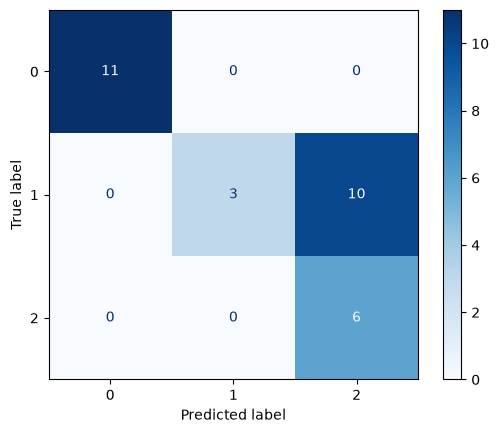

In [134]:
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay(matriz_de_confusao).plot(cmap=plt.cm.Blues)
plt.show()

#### Métricas _Softmax_

In [135]:
y_pred = logisticaSM.predict(X_test)

In [136]:
metricasSM = []
metricasSM.append(accuracy_score(y_test, y_pred))
metricasSM.append(precision_score(y_test, y_pred, average='weighted'))
metricasSM.append(recall_score(y_test, y_pred, average='weighted'))
metricasSM.append(f1_score(y_test, y_pred, average='weighted'))
print("Métricas de avaliação (One-vs-Rest):")
print(f"Accuracy: {metricasSM[0]:.2f}")
print(f"Precision: {metricasSM[1]:.2f}")
print(f"Recall: {metricasSM[2]:.2f}")
print(f"F1-Score: {metricasSM[3]:.2f}")

Métricas de avaliação (One-vs-Rest):
Accuracy: 0.90
Precision: 0.93
Recall: 0.90
F1-Score: 0.90


In [137]:
matriz_de_confusao = confusion_matrix(y_test, y_pred)

<Figure size 800x600 with 0 Axes>

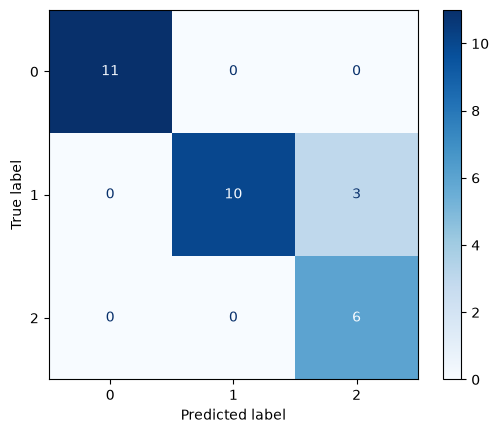

In [138]:
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay(matriz_de_confusao).plot(cmap=plt.cm.Blues)
plt.show()

### Dataset Mnist

Link para o MNIST utilizado aqui no kaggle: https://www.kaggle.com/datasets/hojjatk/mnist-dataset

#### Divisão

In [139]:
caminho = "archive.zip"

In [140]:
X_train = carregar_imagens("train-images.idx3-ubyte")
y_train = carregar_rotulos("train-labels.idx1-ubyte")

In [141]:
X_test = carregar_imagens("t10k-images.idx3-ubyte")
y_test = carregar_rotulos("t10k-labels.idx1-ubyte")

In [142]:
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

Tive que alterar o formato porque do jeito que estava cada exemplo de treinamento era um tensor em $\mathbb{R}^{60000 \cdot 28 \cdot 28}$

#### Modelagem

In [143]:
logistica = RegLogisMulticlasseOneVsRest()
logisticaSM = RegLogisMulticlasseSM()

In [144]:
logisticaSM.fit(X_train, y_train)

In [145]:
logistica.fit(X_train, y_train)
y_pred = logistica.predict(X_test)

#### Métricas _One-vs-Rest_

In [146]:
metricasOvsR = []
metricasOvsR.append(accuracy_score(y_test, y_pred))
metricasOvsR.append(precision_score(y_test, y_pred, average='weighted'))
metricasOvsR.append(recall_score(y_test, y_pred, average='weighted'))
metricasOvsR.append(f1_score(y_test, y_pred, average='weighted'))
print("Métricas de avaliação (One-vs-Rest):")
print(f"Accuracy: {metricasOvsR[0]:.2f}")
print(f"Precision: {metricasOvsR[1]:.2f}")
print(f"Recall: {metricasOvsR[2]:.2f}")
print(f"F1-Score: {metricasOvsR[3]:.2f}")

Métricas de avaliação (One-vs-Rest):
Accuracy: 0.86
Precision: 0.86
Recall: 0.86
F1-Score: 0.85


In [147]:
matriz_de_confusao = confusion_matrix(y_test, y_pred)

<Figure size 800x600 with 0 Axes>

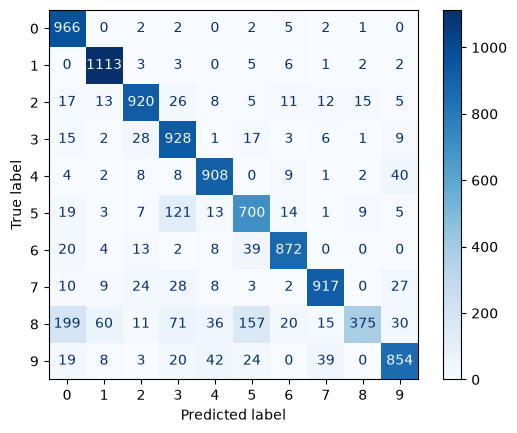

In [148]:
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay(matriz_de_confusao).plot(cmap=plt.cm.Blues)
plt.show()

#### Métricas _Softmax_

In [149]:
y_pred = logisticaSM.predict(X_test)

In [150]:
metricasSM = []
metricasSM.append(accuracy_score(y_test, y_pred))
metricasSM.append(precision_score(y_test, y_pred, average='weighted'))
metricasSM.append(recall_score(y_test, y_pred, average='weighted'))
metricasSM.append(f1_score(y_test, y_pred, average='weighted'))
print("Métricas de avaliação (One-vs-Rest):")
print(f"Accuracy: {metricasSM[0]:.2f}")
print(f"Precision: {metricasSM[1]:.2f}")
print(f"Recall: {metricasSM[2]:.2f}")
print(f"F1-Score: {metricasSM[3]:.2f}")

Métricas de avaliação (One-vs-Rest):
Accuracy: 0.90
Precision: 0.91
Recall: 0.90
F1-Score: 0.90


In [151]:
matriz_de_confusao = confusion_matrix(y_test, y_pred)

<Figure size 800x600 with 0 Axes>

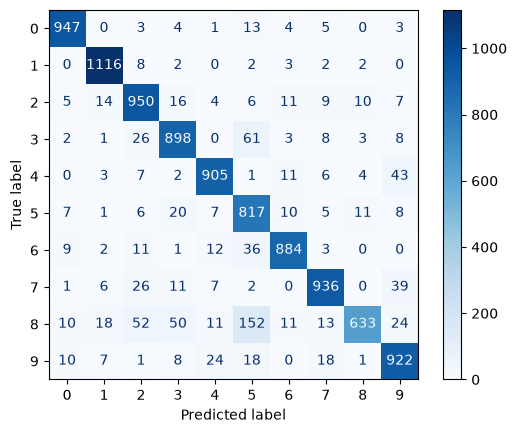

In [152]:
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay(matriz_de_confusao).plot(cmap=plt.cm.Blues)
plt.show()